# 👩‍💼👨‍💼 Analyse des salaires par sexe

**Objectif** : Analyser les écarts de rémunération entre hommes et femmes dans la fonction publique ivoirienne,
à partir du fichier `indicateurs_salaire_brut_2024_2025_avec_zeros_SOMMAIRE_200426.xlsx`.

**Sources des données** :
- Feuilles `BAREME_S_*` : indicateurs par **Barème × Sexe** (effectif, revenu moyen, médian, min, max, p25, p75)
- Données mensuelles de janvier 2024 à décembre 2025

**Plan d'analyse** :
1. Charger et consolider les données par sexe
2. Vue globale des effectifs et revenus par sexe
3. Évolution temporelle des écarts H/F
4. Analyse par barème / grille salariale
5. Distribution des revenus (P25, médiane, P75)
6. Synthèse et export

## 📦 1. Imports et configuration

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import warnings
warnings.filterwarnings('ignore')

# Style graphique
plt.rcParams.update({
    'figure.figsize': (14, 6),
    'figure.dpi': 100,
    'font.size': 11,
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'legend.fontsize': 11,
})

# Couleurs
COLOR_F = '#E91E63'   # Rose / Femme
COLOR_H = '#1976D2'   # Bleu / Homme
COLOR_ECART = '#FF9800'  # Orange / Écart

PATH_INDICATEURS = "indicateurs_salaire_brut_2024_2025_avec_zeros_SOMMAIRE_200426.xlsx"

# Formateur pour les montants en FCFA
def fmt_fcfa(x, pos=None):
    if abs(x) >= 1_000_000:
        return f'{x/1_000_000:.1f}M'
    elif abs(x) >= 1_000:
        return f'{x/1_000:.0f}k'
    return f'{x:.0f}'

print("✅ Imports OK")

✅ Imports OK


## 📂 2. Chargement des données par sexe

On charge toutes les feuilles `BAREME_S_*` qui contiennent les indicateurs ventilés par **Barème × Sexe**.

In [3]:
xls = pd.ExcelFile(PATH_INDICATEURS)

# Identifier les feuilles BAREME_S
bareme_s_sheets = [s for s in xls.sheet_names if s.startswith('BAREME_S_')]
print(f"📋 {len(bareme_s_sheets)} feuilles BAREME_S trouvées :")
for s in bareme_s_sheets:
    print(f"   • {s}")

# Charger et concaténer
dfs = []
for sheet in bareme_s_sheets:
    df = pd.read_excel(xls, sheet_name=sheet, header=None)
    header_row = df.iloc[3].tolist()
    df_data = df.iloc[4:].copy()
    df_data.columns = header_row
    df_data = df_data.reset_index(drop=True)
    for col in ['ANNEE', 'MOIS_NUM', 'Effectif', 'Revenu_moyen', 'Revenu_median',
                'Revenu_min', 'Revenu_max', 'Revenu_p25', 'Revenu_p75']:
        if col in df_data.columns:
            df_data[col] = pd.to_numeric(df_data[col], errors='coerce')
    dfs.append(df_data)

df_sexe = pd.concat(dfs, ignore_index=True)

# Créer colonne date pour faciliter les graphiques
df_sexe['date'] = pd.to_datetime(
    df_sexe['ANNEE'].astype(int).astype(str) + '-' + df_sexe['MOIS_NUM'].astype(int).astype(str) + '-01'
)

print(f"\n✅ {len(df_sexe)} lignes chargées")
print(f"Années  : {sorted(df_sexe['ANNEE'].unique())}")
print(f"Sexes   : {df_sexe['SEXE_STD'].unique().tolist()}")
print(f"Barèmes : {sorted(df_sexe['bareme'].unique())}")
df_sexe.head()

📋 11 feuilles BAREME_S trouvées :
   • BAREME_S_Bar_me_G_n_ral
   • BAREME_S_CORPS_DIPL
   • BAREME_S_CORPS_PREF
   • BAREME_S_Cadre_Sup_Sant_
   • BAREME_S_ENS_SEC___PRIM
   • BAREME_S_ENS_SUP
   • BAREME_S_GREFFE
   • BAREME_S_Informaticien
   • BAREME_S_MAGISTRAT_
   • BAREME_S_SECRETAIRE_DIRECTION
   • BAREME_S_Tech_Sant_

✅ 528 lignes chargées
Années  : [np.int64(2024), np.int64(2025)]
Sexes   : ['Femme', 'Homme']
Barèmes : ['Barême Général', 'CORPS DIPL', 'CORPS PREF', 'Cadre-Sup-Santé', 'ENS SEC & PRIM', 'ENS SUP', 'GREFFE', 'Informaticien', 'MAGISTRAT ', 'SECRETAIRE DIRECTION', 'Tech-Santé']


,ANNEE,MOIS_NUM,MOIS,bareme,SEXE_STD,Effectif,Revenu_moyen,Revenu_median,Revenu_min,Revenu_max,Revenu_p25,Revenu_p75,date
0,2024,1,Janvier,Barême Général,Femme,17150,307879,284996,191418,760916,230765,350974,2024-01-01
1,2024,1,Janvier,Barême Général,Homme,35622,322046,282427,191417,768416,240765,365974,2024-01-01
2,2024,2,Février,Barême Général,Femme,17509,311498,288486,191418,775351,232895,355042,2024-02-01
3,2024,2,Février,Barême Général,Homme,35978,324816,283486,191417,780954,241134,369810,2024-02-01
4,2024,3,Mars,Barême Général,Femme,17871,309232,285752,191418,760916,232894,350052,2024-03-01


## 📊 3. Vue globale : Effectifs par sexe

On agrège les effectifs tous barèmes confondus pour obtenir la répartition H/F sur la période.

In [4]:
# Effectifs globaux par sexe et mois
df_eff_global = (
    df_sexe
    .groupby(['date', 'ANNEE', 'MOIS_NUM', 'SEXE_STD'])
    .agg(Effectif_total=('Effectif', 'sum'))
    .reset_index()
)

# Pivoter pour avoir Femme et Homme côte à côte
df_eff_pivot = df_eff_global.pivot_table(
    index=['date', 'ANNEE', 'MOIS_NUM'],
    columns='SEXE_STD',
    values='Effectif_total'
).reset_index()

df_eff_pivot['Total'] = df_eff_pivot['Femme'] + df_eff_pivot['Homme']
df_eff_pivot['Part_Femme_%'] = (df_eff_pivot['Femme'] / df_eff_pivot['Total'] * 100).round(1)

print("📊 Effectifs globaux par sexe et mois :")
df_eff_pivot

📊 Effectifs globaux par sexe et mois :


SEXE_STD,date,ANNEE,MOIS_NUM,Femme,Homme,Total,Part_Femme_%
0,2024-01-01,2024,1,94109.0,159589.0,253698.0,37.1
1,2024-02-01,2024,2,94950.0,160474.0,255424.0,37.2
2,2024-03-01,2024,3,96324.0,162017.0,258341.0,37.3
3,2024-04-01,2024,4,97210.0,162966.0,260176.0,37.4
4,2024-05-01,2024,5,97253.0,162740.0,259993.0,37.4
5,2024-06-01,2024,6,97689.0,163136.0,260825.0,37.5
6,2024-07-01,2024,7,98714.0,164951.0,263665.0,37.4
7,2024-08-01,2024,8,99587.0,166004.0,265591.0,37.5
8,2024-09-01,2024,9,100481.0,167082.0,267563.0,37.6
9,2024-10-01,2024,10,102447.0,168210.0,270657.0,37.9


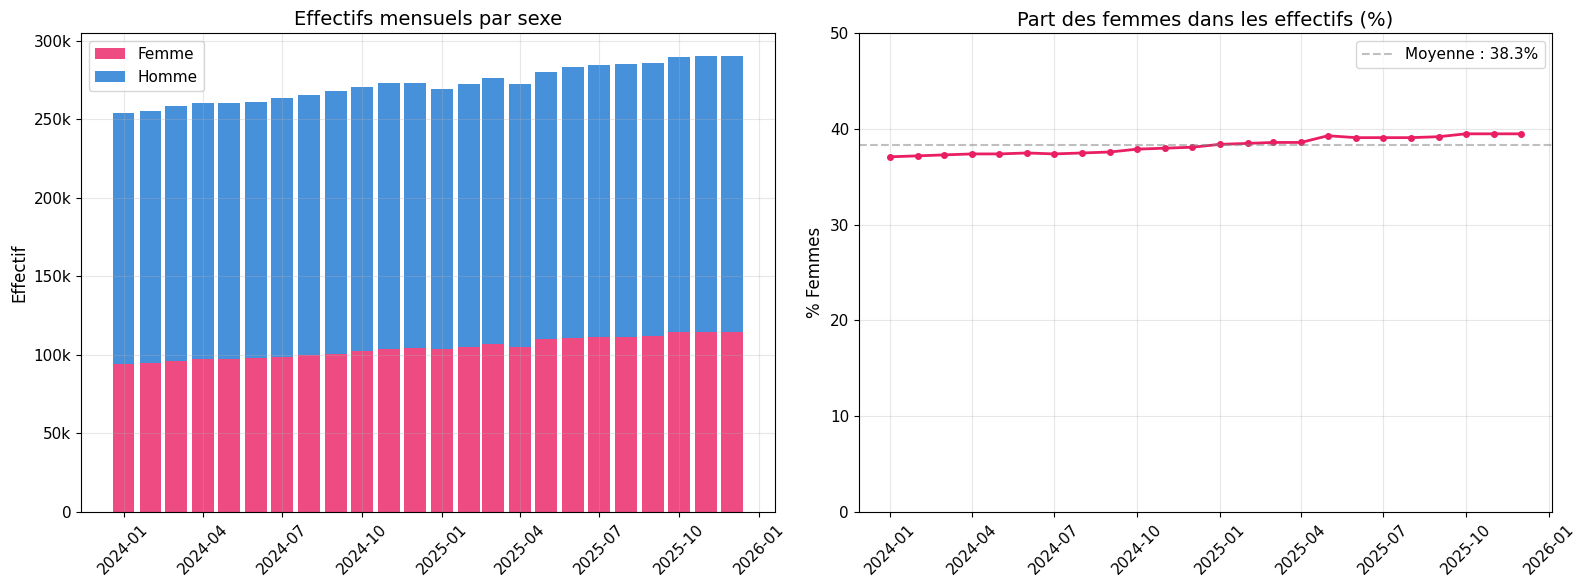

💾 Graphique sauvegardé : effectifs_par_sexe.png


In [5]:
# Graphique : Évolution des effectifs par sexe
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# --- Panel 1 : Effectifs ---
ax1.bar(df_eff_pivot['date'], df_eff_pivot['Femme'], label='Femme', color=COLOR_F, alpha=0.8, width=25)
ax1.bar(df_eff_pivot['date'], df_eff_pivot['Homme'], bottom=df_eff_pivot['Femme'],
        label='Homme', color=COLOR_H, alpha=0.8, width=25)
ax1.set_title('Effectifs mensuels par sexe')
ax1.set_ylabel('Effectif')
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(fmt_fcfa))
ax1.legend()
ax1.tick_params(axis='x', rotation=45)

# --- Panel 2 : Part des femmes ---
ax2.plot(df_eff_pivot['date'], df_eff_pivot['Part_Femme_%'], color=COLOR_F,
         marker='o', markersize=4, linewidth=2)
ax2.axhline(y=df_eff_pivot['Part_Femme_%'].mean(), color='gray', linestyle='--', alpha=0.5,
            label=f"Moyenne : {df_eff_pivot['Part_Femme_%'].mean():.1f}%")
ax2.set_title('Part des femmes dans les effectifs (%)')
ax2.set_ylabel('% Femmes')
ax2.set_ylim(0, 50)
ax2.legend()
ax2.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('effectifs_par_sexe.png', bbox_inches='tight', dpi=150)
plt.show()
print("💾 Graphique sauvegardé : effectifs_par_sexe.png")

## 💰 4. Vue globale : Revenus moyens par sexe

On calcule la moyenne pondérée des revenus par sexe (pondérée par les effectifs de chaque barème).

In [6]:
# Revenu moyen pondéré par sexe et mois (tous barèmes confondus)
df_sexe['rev_x_eff'] = df_sexe['Revenu_moyen'] * df_sexe['Effectif']

df_rev_global = (
    df_sexe
    .groupby(['date', 'ANNEE', 'MOIS_NUM', 'SEXE_STD'])
    .agg(
        Effectif_total=('Effectif', 'sum'),
        rev_x_eff_total=('rev_x_eff', 'sum')
    )
    .reset_index()
)

df_rev_global['Revenu_moyen_pondere'] = (
    df_rev_global['rev_x_eff_total'] / df_rev_global['Effectif_total']
).round(0)

# Pivoter
df_rev_pivot = df_rev_global.pivot_table(
    index=['date', 'ANNEE', 'MOIS_NUM'],
    columns='SEXE_STD',
    values='Revenu_moyen_pondere'
).reset_index()

df_rev_pivot.columns.name = None
df_rev_pivot.rename(columns={'Femme': 'Rev_moy_Femme', 'Homme': 'Rev_moy_Homme'}, inplace=True)

# Calcul de l'écart
df_rev_pivot['Ecart_HF'] = df_rev_pivot['Rev_moy_Homme'] - df_rev_pivot['Rev_moy_Femme']
df_rev_pivot['Ecart_HF_%'] = (
    (df_rev_pivot['Ecart_HF'] / df_rev_pivot['Rev_moy_Femme']) * 100
).round(1)

print("📊 Revenus moyens pondérés par sexe :")
df_rev_pivot

📊 Revenus moyens pondérés par sexe :


,date,ANNEE,MOIS_NUM,Rev_moy_Femme,Rev_moy_Homme,Ecart_HF,Ecart_HF_%
0,2024-01-01,2024,1,382147.0,453791.0,71644.0,18.7
1,2024-02-01,2024,2,385999.0,458442.0,72443.0,18.8
2,2024-03-01,2024,3,384216.0,456075.0,71859.0,18.7
3,2024-04-01,2024,4,382605.0,454150.0,71545.0,18.7
4,2024-05-01,2024,5,382575.0,453770.0,71195.0,18.6
5,2024-06-01,2024,6,382459.0,453825.0,71366.0,18.7
6,2024-07-01,2024,7,383075.0,455363.0,72288.0,18.9
7,2024-08-01,2024,8,385547.0,457442.0,71895.0,18.6
8,2024-09-01,2024,9,383150.0,455596.0,72446.0,18.9
9,2024-10-01,2024,10,382574.0,455593.0,73019.0,19.1


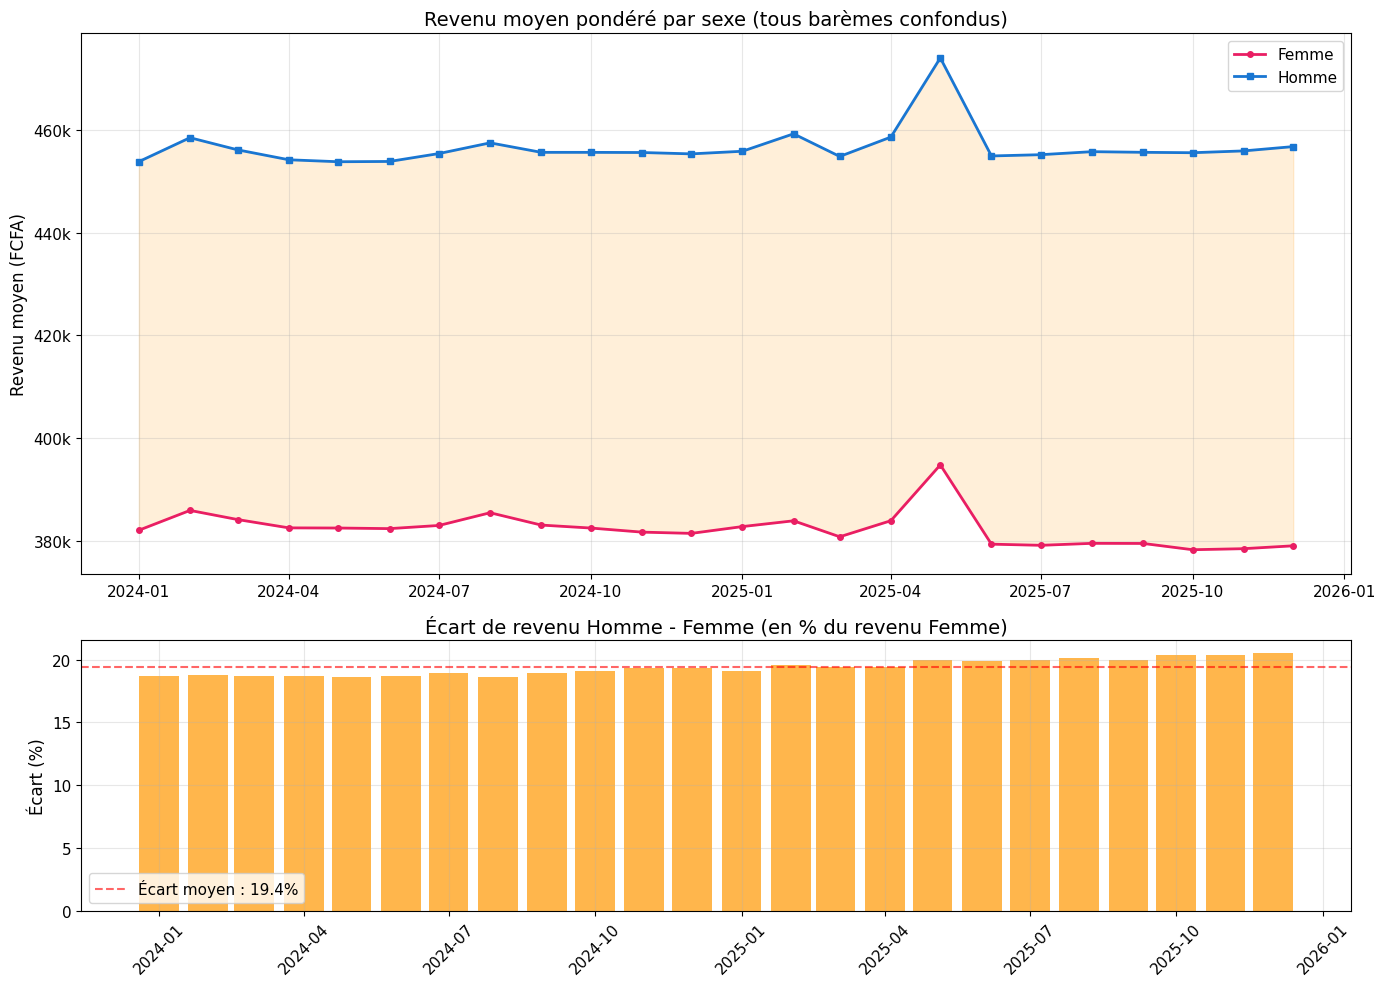

💾 Graphique sauvegardé : revenus_par_sexe_global.png


In [7]:
# Graphique : Revenus moyens par sexe + écart
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10), gridspec_kw={'height_ratios': [2, 1]})

# --- Panel 1 : Revenus moyens ---
ax1.plot(df_rev_pivot['date'], df_rev_pivot['Rev_moy_Femme'], color=COLOR_F,
         marker='o', markersize=4, linewidth=2, label='Femme')
ax1.plot(df_rev_pivot['date'], df_rev_pivot['Rev_moy_Homme'], color=COLOR_H,
         marker='s', markersize=4, linewidth=2, label='Homme')
ax1.fill_between(df_rev_pivot['date'], df_rev_pivot['Rev_moy_Femme'],
                 df_rev_pivot['Rev_moy_Homme'], alpha=0.15, color=COLOR_ECART)
ax1.set_title('Revenu moyen pondéré par sexe (tous barèmes confondus)')
ax1.set_ylabel('Revenu moyen (FCFA)')
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(fmt_fcfa))
ax1.legend()

# --- Panel 2 : Écart en % ---
ax2.bar(df_rev_pivot['date'], df_rev_pivot['Ecart_HF_%'], color=COLOR_ECART, alpha=0.7, width=25)
ax2.axhline(y=df_rev_pivot['Ecart_HF_%'].mean(), color='red', linestyle='--', alpha=0.6,
            label=f"Écart moyen : {df_rev_pivot['Ecart_HF_%'].mean():.1f}%")
ax2.set_title('Écart de revenu Homme - Femme (en % du revenu Femme)')
ax2.set_ylabel('Écart (%)')
ax2.legend()
ax2.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('revenus_par_sexe_global.png', bbox_inches='tight', dpi=150)
plt.show()
print("💾 Graphique sauvegardé : revenus_par_sexe_global.png")

## 📊 5. Analyse par Barème / Grille salariale

On compare les revenus H/F au sein de chaque barème pour identifier où les écarts sont les plus marqués.

In [8]:
# Revenus moyens par barème et sexe sur toute la période
df_rev_bareme = (
    df_sexe
    .groupby(['bareme', 'SEXE_STD'])
    .agg(
        Effectif_total=('Effectif', 'sum'),
        rev_x_eff_total=('rev_x_eff', 'sum'),
        Revenu_min=('Revenu_min', 'min'),
        Revenu_max=('Revenu_max', 'max'),
    )
    .reset_index()
)

df_rev_bareme['Revenu_moyen'] = (df_rev_bareme['rev_x_eff_total'] / df_rev_bareme['Effectif_total']).round(0)

# Pivoter pour comparaison
df_comp_bareme = df_rev_bareme.pivot_table(
    index='bareme',
    columns='SEXE_STD',
    values=['Effectif_total', 'Revenu_moyen', 'Revenu_min', 'Revenu_max']
).reset_index()

# Aplatir les colonnes multi-niveaux
df_comp_bareme.columns = ['_'.join(col).strip('_') for col in df_comp_bareme.columns.values]

# Calculer l'écart
df_comp_bareme['Ecart_rev_moy'] = df_comp_bareme['Revenu_moyen_Homme'] - df_comp_bareme['Revenu_moyen_Femme']
df_comp_bareme['Ecart_rev_%'] = (
    (df_comp_bareme['Ecart_rev_moy'] / df_comp_bareme['Revenu_moyen_Femme']) * 100
).round(1)

# Part des femmes
df_comp_bareme['Part_Femme_%'] = (
    df_comp_bareme['Effectif_total_Femme'] /
    (df_comp_bareme['Effectif_total_Femme'] + df_comp_bareme['Effectif_total_Homme']) * 100
).round(1)

# Trier par écart décroissant
df_comp_bareme = df_comp_bareme.sort_values('Ecart_rev_%', ascending=False)

print("📊 Comparaison H/F par barème (trié par écart décroissant) :")
cols_display = ['bareme', 'Effectif_total_Femme', 'Effectif_total_Homme', 'Part_Femme_%',
                'Revenu_moyen_Femme', 'Revenu_moyen_Homme', 'Ecart_rev_moy', 'Ecart_rev_%']
df_comp_bareme[cols_display]

📊 Comparaison H/F par barème (trié par écart décroissant) :


,bareme,Effectif_total_Femme,Effectif_total_Homme,Part_Femme_%,Revenu_moyen_Femme,Revenu_moyen_Homme,Ecart_rev_moy,Ecart_rev_%
4,ENS SEC & PRIM,1350598.0,2395326.0,36.1,425402.0,501122.0,75720.0,17.8
1,CORPS DIPL,1315.0,2747.0,32.4,702633.0,808907.0,106274.0,15.1
10,Tech-Santé,453884.0,349337.0,56.5,304689.0,339402.0,34713.0,11.4
6,GREFFE,8331.0,18514.0,31.0,419383.0,456441.0,37058.0,8.8
3,Cadre-Sup-Santé,50877.0,105009.0,32.6,522614.0,555478.0,32864.0,6.3
5,ENS SUP,26034.0,111794.0,18.9,846663.0,893299.0,46636.0,5.5
0,Barême Général,465816.0,906276.0,33.9,310036.0,325195.0,15159.0,4.9
2,CORPS PREF,2010.0,7817.0,20.5,789260.0,819717.0,30457.0,3.9
9,SECRETAIRE DIRECTION,122555.0,55345.0,68.9,284511.0,294993.0,10482.0,3.7
7,Informaticien,18973.0,70799.0,21.1,340567.0,352841.0,12274.0,3.6


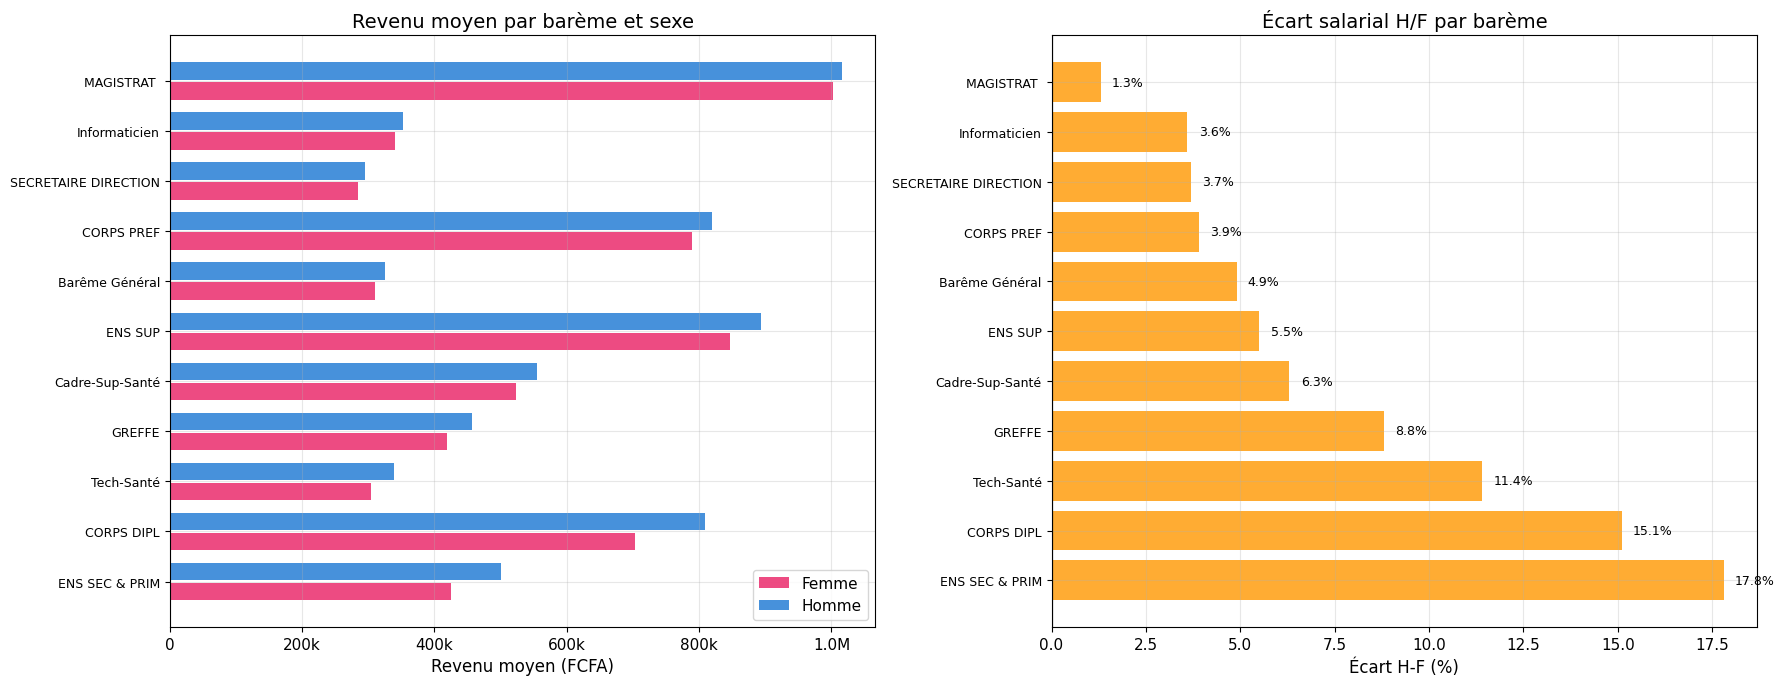

💾 Graphique sauvegardé : ecart_par_bareme.png


In [9]:
# Graphique : Écart de revenu par barème
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7))

baremes = df_comp_bareme['bareme'].values
y_pos = np.arange(len(baremes))

# --- Panel 1 : Revenu moyen comparé ---
ax1.barh(y_pos - 0.2, df_comp_bareme['Revenu_moyen_Femme'], 0.35,
         label='Femme', color=COLOR_F, alpha=0.8)
ax1.barh(y_pos + 0.2, df_comp_bareme['Revenu_moyen_Homme'], 0.35,
         label='Homme', color=COLOR_H, alpha=0.8)
ax1.set_yticks(y_pos)
ax1.set_yticklabels(baremes, fontsize=9)
ax1.set_xlabel('Revenu moyen (FCFA)')
ax1.set_title('Revenu moyen par barème et sexe')
ax1.xaxis.set_major_formatter(mticker.FuncFormatter(fmt_fcfa))
ax1.legend()

# --- Panel 2 : Écart en % ---
colors_bar = [COLOR_ECART if e > 0 else '#4CAF50' for e in df_comp_bareme['Ecart_rev_%']]
ax2.barh(y_pos, df_comp_bareme['Ecart_rev_%'], color=colors_bar, alpha=0.8)
ax2.axvline(x=0, color='black', linewidth=0.8)
ax2.set_yticks(y_pos)
ax2.set_yticklabels(baremes, fontsize=9)
ax2.set_xlabel('Écart H-F (%)')
ax2.set_title('Écart salarial H/F par barème')
# Annoter les valeurs
for i, v in enumerate(df_comp_bareme['Ecart_rev_%']):
    ax2.text(v + 0.3, i, f'{v:.1f}%', va='center', fontsize=9)

plt.tight_layout()
plt.savefig('ecart_par_bareme.png', bbox_inches='tight', dpi=150)
plt.show()
print("💾 Graphique sauvegardé : ecart_par_bareme.png")

## 📈 6. Évolution temporelle par barème

On visualise l'évolution mois par mois de l'écart H/F pour les principaux barèmes.

In [ ]:
# Calculer l'écart mois par mois par barème
df_evol = df_sexe.pivot_table(
    index=['date', 'bareme', 'ANNEE', 'MOIS_NUM'],
    columns='SEXE_STD',
    values=['Revenu_moyen', 'Effectif']
).reset_index()

df_evol.columns = ['_'.join(col).strip('_') for col in df_evol.columns.values]
df_evol['Ecart_%'] = (
    (df_evol['Revenu_moyen_Homme'] - df_evol['Revenu_moyen_Femme'])
    / df_evol['Revenu_moyen_Femme'] * 100
).round(1)

# Top barèmes par effectif
top_baremes = (
    df_sexe.groupby('bareme')['Effectif'].sum()
    .nlargest(6).index.tolist()
)

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, bareme in enumerate(top_baremes):
    ax = axes[i]
    df_b = df_evol[df_evol['bareme'] == bareme].sort_values('date')
    
    ax.plot(df_b['date'], df_b['Revenu_moyen_Femme'], color=COLOR_F,
            marker='.', linewidth=1.5, label='Femme')
    ax.plot(df_b['date'], df_b['Revenu_moyen_Homme'], color=COLOR_H,
            marker='.', linewidth=1.5, label='Homme')
    ax.fill_between(df_b['date'], df_b['Revenu_moyen_Femme'],
                    df_b['Revenu_moyen_Homme'], alpha=0.1, color=COLOR_ECART)
    ax.set_title(bareme, fontsize=10, fontweight='bold')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(fmt_fcfa))
    ax.tick_params(axis='x', rotation=45, labelsize=8)
    if i == 0:
        ax.legend(fontsize=8)

plt.suptitle('Évolution du revenu moyen par sexe — Top 6 barèmes', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig('evolution_revenus_par_bareme_sexe.png', bbox_inches='tight', dpi=150)
plt.show()
print("💾 Graphique sauvegardé : evolution_revenus_par_bareme_sexe.png")

## 📊 7. Distribution des revenus par sexe

On compare les quartiles (P25, Médiane, P75) entre hommes et femmes pour chaque barème
afin de mieux comprendre la structure de la distribution salariale.

In [10]:
# Moyennes des indicateurs de distribution sur toute la période
df_distrib = (
    df_sexe
    .groupby(['bareme', 'SEXE_STD'])
    .agg(
        P25_moy=('Revenu_p25', 'mean'),
        Median_moy=('Revenu_median', 'mean'),
        P75_moy=('Revenu_p75', 'mean'),
        Min_moy=('Revenu_min', 'mean'),
        Max_moy=('Revenu_max', 'mean'),
        Effectif_total=('Effectif', 'sum'),
    )
    .reset_index()
    .round(0)
)

print("📊 Distribution des revenus par barème et sexe :")
df_distrib

📊 Distribution des revenus par barème et sexe :


,bareme,SEXE_STD,P25_moy,Median_moy,P75_moy,Min_moy,Max_moy,Effectif_total
0,Barême Général,Femme,233146.0,290110.0,349247.0,191418.0,766304.0,465816
1,Barême Général,Homme,242085.0,287788.0,367080.0,191418.0,775651.0,906276
2,CORPS DIPL,Femme,579291.0,653184.0,842294.0,516065.0,1051540.0,1315
3,CORPS DIPL,Homme,723281.0,860105.0,895929.0,512413.0,1074889.0,2747
4,CORPS PREF,Femme,719673.0,761896.0,816605.0,688625.0,1038291.0,2010
5,CORPS PREF,Homme,739985.0,807390.0,905719.0,686976.0,1197043.0,7817
6,Cadre-Sup-Santé,Femme,437979.0,479539.0,585446.0,407405.0,814008.0,50877
7,Cadre-Sup-Santé,Homme,450560.0,522867.0,671875.0,407405.0,832816.0,105009
8,ENS SEC & PRIM,Femme,321406.0,410564.0,482900.0,266776.0,1028419.0,1350598
9,ENS SEC & PRIM,Homme,405568.0,474243.0,578373.0,266776.0,1053477.0,2395326


In [ ]:
# Graphique : Box-plot style avec P25, Median, P75 par barème et sexe
baremes_sorted = sorted(df_sexe['bareme'].unique())

fig, ax = plt.subplots(figsize=(16, 8))

y_pos = np.arange(len(baremes_sorted))
offset = 0.18

for idx, sexe in enumerate(['Femme', 'Homme']):
    color = COLOR_F if sexe == 'Femme' else COLOR_H
    y_offset = -offset if sexe == 'Femme' else offset
    
    df_s = df_distrib[df_distrib['SEXE_STD'] == sexe].set_index('bareme').reindex(baremes_sorted)
    
    # Barre P25 → P75
    ax.barh(y_pos + y_offset,
            df_s['P75_moy'] - df_s['P25_moy'],
            left=df_s['P25_moy'],
            height=0.3, color=color, alpha=0.4, label=f'{sexe} (P25-P75)')
    
    # Point pour la médiane
    ax.scatter(df_s['Median_moy'], y_pos + y_offset,
              color=color, s=60, zorder=5, marker='|', linewidths=2)
    
    # Lignes Min → Max
    for i, bareme in enumerate(baremes_sorted):
        if bareme in df_s.index:
            ax.plot([df_s.loc[bareme, 'Min_moy'], df_s.loc[bareme, 'Max_moy']],
                    [i + y_offset, i + y_offset],
                    color=color, alpha=0.5, linewidth=1)

ax.set_yticks(y_pos)
ax.set_yticklabels(baremes_sorted, fontsize=9)
ax.set_xlabel('Revenu (FCFA)')
ax.set_title('Distribution des revenus par barème et sexe (Min — P25 ▮ Médiane ▮ P75 — Max)')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(fmt_fcfa))
ax.legend(loc='lower right', fontsize=9)

plt.tight_layout()
plt.savefig('distribution_revenus_sexe.png', bbox_inches='tight', dpi=150)
plt.show()
print("💾 Graphique sauvegardé : distribution_revenus_sexe.png")

## 📊 8. Écart de revenu médian par barème

L'écart sur la **médiane** est un indicateur plus robuste que la moyenne car moins sensible aux valeurs extrêmes.

In [ ]:
# Pivoter pour obtenir médiane H vs F
df_median = df_distrib.pivot_table(
    index='bareme',
    columns='SEXE_STD',
    values='Median_moy'
).reset_index()

df_median['Ecart_median'] = df_median['Homme'] - df_median['Femme']
df_median['Ecart_median_%'] = ((df_median['Ecart_median'] / df_median['Femme']) * 100).round(1)
df_median = df_median.sort_values('Ecart_median_%', ascending=True)

# Graphique
fig, ax = plt.subplots(figsize=(12, 7))

colors = [COLOR_ECART if e > 0 else '#4CAF50' for e in df_median['Ecart_median_%']]
bars = ax.barh(df_median['bareme'], df_median['Ecart_median_%'], color=colors, alpha=0.8)
ax.axvline(x=0, color='black', linewidth=0.8)
ax.set_xlabel('Écart médiane H-F (%)')
ax.set_title('Écart de revenu MÉDIAN entre Hommes et Femmes par barème')

# Annoter
for bar, v in zip(bars, df_median['Ecart_median_%']):
    ax.text(v + (0.3 if v >= 0 else -2), bar.get_y() + bar.get_height()/2,
            f'{v:.1f}%', va='center', fontsize=9)

plt.tight_layout()
plt.savefig('ecart_median_par_bareme.png', bbox_inches='tight', dpi=150)
plt.show()
print("💾 Graphique sauvegardé : ecart_median_par_bareme.png")

## 👥 9. Répartition des effectifs H/F par barème

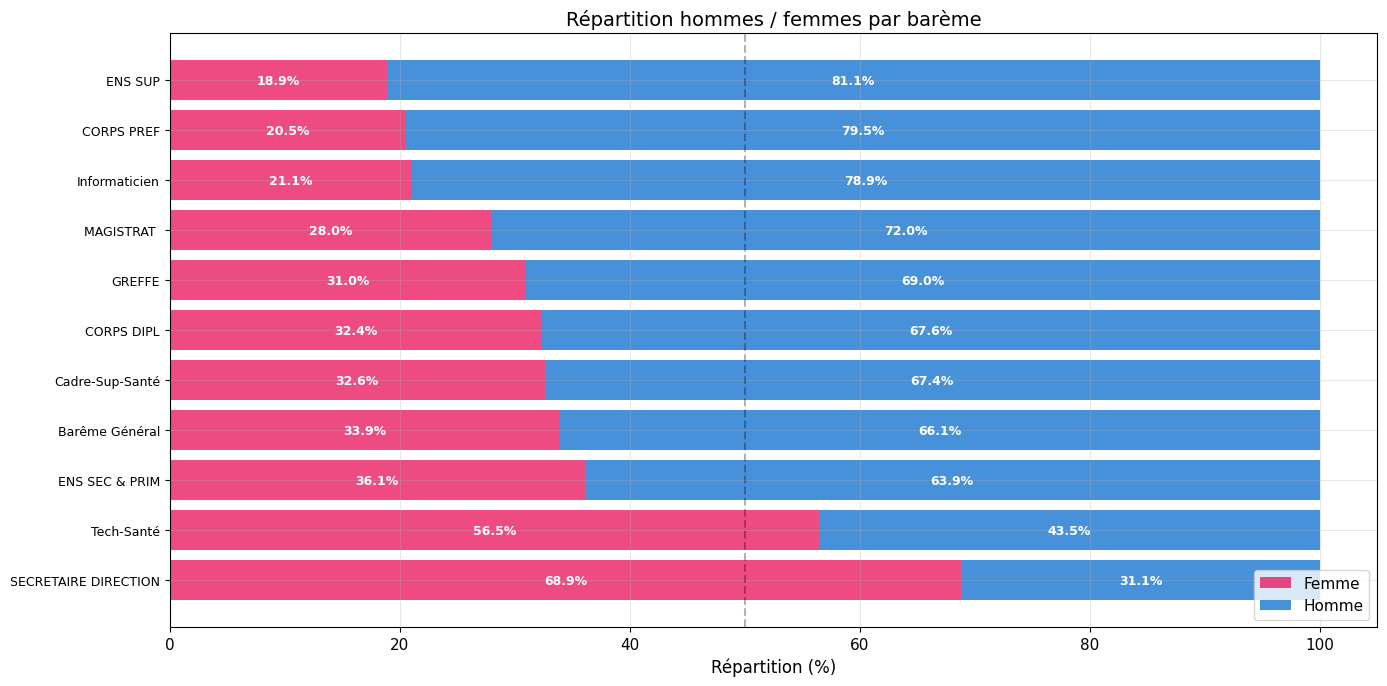

💾 Graphique sauvegardé : repartition_hf_par_bareme.png


In [11]:
# Part des femmes par barème
df_part = df_comp_bareme[['bareme', 'Part_Femme_%', 'Effectif_total_Femme', 'Effectif_total_Homme']].copy()
df_part['Part_Homme_%'] = 100 - df_part['Part_Femme_%']
df_part = df_part.sort_values('Part_Femme_%', ascending=False)

fig, ax = plt.subplots(figsize=(14, 7))

y_pos = np.arange(len(df_part))
ax.barh(y_pos, df_part['Part_Femme_%'], color=COLOR_F, alpha=0.8, label='Femme')
ax.barh(y_pos, df_part['Part_Homme_%'], left=df_part['Part_Femme_%'],
        color=COLOR_H, alpha=0.8, label='Homme')

ax.set_yticks(y_pos)
ax.set_yticklabels(df_part['bareme'], fontsize=9)
ax.axvline(x=50, color='black', linestyle='--', alpha=0.3)
ax.set_xlabel('Répartition (%)')
ax.set_title('Répartition hommes / femmes par barème')
ax.legend(loc='lower right')

# Annoter les %
for i, row in enumerate(df_part.itertuples()):
    ax.text(row._2 / 2, i, f'{row._2:.1f}%', va='center', ha='center',
            fontsize=9, color='white', fontweight='bold')
    ax.text(row._2 + row._5 / 2, i, f'{row._5:.1f}%', va='center', ha='center',
            fontsize=9, color='white', fontweight='bold')

plt.tight_layout()
plt.savefig('repartition_hf_par_bareme.png', bbox_inches='tight', dpi=150)
plt.show()
print("💾 Graphique sauvegardé : repartition_hf_par_bareme.png")

## 🔍 10. Comparaison Min et Max par sexe et barème

On compare les salaires minimum et maximum observés par sexe pour détecter des plafonds de verre.

In [12]:
# Tableau min/max par sexe
df_minmax = df_rev_bareme.pivot_table(
    index='bareme',
    columns='SEXE_STD',
    values=['Revenu_min', 'Revenu_max']
).reset_index()

df_minmax.columns = ['_'.join(col).strip('_') for col in df_minmax.columns.values]

# Écart sur le max
df_minmax['Ecart_max_HF'] = df_minmax['Revenu_max_Homme'] - df_minmax['Revenu_max_Femme']
df_minmax['Ecart_min_HF'] = df_minmax['Revenu_min_Homme'] - df_minmax['Revenu_min_Femme']

print("📊 Min et Max des revenus par barème et sexe :")
print("=" * 100)
df_minmax.sort_values('Ecart_max_HF', ascending=False)

📊 Min et Max des revenus par barème et sexe :


,bareme,Revenu_max_Femme,Revenu_max_Homme,Revenu_min_Femme,Revenu_min_Homme,Ecart_max_HF,Ecart_min_HF
7,Informaticien,716541.0,780217.0,255297.0,239743.0,63676.0,-15554.0
4,ENS SEC & PRIM,1086533.0,1120700.0,266776.0,266776.0,34167.0,0.0
5,ENS SUP,1490529.0,1514138.0,659167.0,656667.0,23609.0,-2500.0
10,Tech-Santé,694918.0,707591.0,204237.0,204237.0,12673.0,0.0
3,Cadre-Sup-Santé,853004.0,858844.0,407405.0,407405.0,5840.0,0.0
2,CORPS PREF,1523585.0,1523585.0,686976.0,686975.0,0.0,-1.0
1,CORPS DIPL,1099725.0,1099723.0,477946.0,477947.0,-2.0,1.0
0,Barême Général,787145.0,787121.0,191418.0,191417.0,-24.0,-1.0
8,MAGISTRAT,1529212.0,1528451.0,690287.0,690287.0,-761.0,0.0
6,GREFFE,851336.0,849332.0,309915.0,309915.0,-2004.0,0.0


## 📊 11. Tableau de synthèse

In [14]:
# Synthèse finale
df_synthese = df_comp_bareme[[
    'bareme', 'Effectif_total_Femme', 'Effectif_total_Homme', 'Part_Femme_%',
    'Revenu_moyen_Femme', 'Revenu_moyen_Homme', 'Ecart_rev_moy', 'Ecart_rev_%'
]].copy()

# Ajouter médiane
df_med = df_median[['bareme', 'Femme', 'Homme', 'Ecart_median_%']].copy()
df_med.rename(columns={'Femme': 'Median_Femme', 'Homme': 'Median_Homme'}, inplace=True)
df_synthese = df_synthese.merge(df_med, on='bareme', how='left')

# Formater
for col in ['Revenu_moyen_Femme', 'Revenu_moyen_Homme', 'Ecart_rev_moy',
            'Median_Femme', 'Median_Homme']:
    df_synthese[col] = df_synthese[col].apply(lambda x: f'{x:,.0f}')

for col in ['Effectif_total_Femme', 'Effectif_total_Homme']:
    df_synthese[col] = df_synthese[col].apply(lambda x: f'{x:,.0f}')

print("📊 SYNTHÈSE : Analyse des salaires par sexe et barème")
print("=" * 120)
df_synthese

NameError: name 'df_median' is not defined

## 💾 12. Export des résultats

In [ ]:
with pd.ExcelWriter('analyse_salaires_par_sexe.xlsx', engine='openpyxl') as writer:
    # Synthèse par barème
    df_comp_bareme.to_excel(writer, sheet_name='Synthese_par_bareme', index=False)
    
    # Effectifs globaux par mois
    df_eff_pivot.to_excel(writer, sheet_name='Effectifs_mensuels', index=False)
    
    # Revenus moyens globaux par mois
    df_rev_pivot.to_excel(writer, sheet_name='Revenus_mensuels', index=False)
    
    # Distribution
    df_distrib.to_excel(writer, sheet_name='Distribution_quartiles', index=False)
    
    # Écart médian
    df_median.to_excel(writer, sheet_name='Ecart_median', index=False)
    
    # Min/Max par sexe
    df_minmax.to_excel(writer, sheet_name='Min_Max_par_sexe', index=False)
    
    # Données brutes
    df_sexe.drop(columns=['rev_x_eff']).to_excel(writer, sheet_name='Donnees_brutes', index=False)

print("✅ Résultats exportés dans 'analyse_salaires_par_sexe.xlsx'")
print("   Feuilles : Synthese_par_bareme, Effectifs_mensuels, Revenus_mensuels,")
print("              Distribution_quartiles, Ecart_median, Min_Max_par_sexe, Donnees_brutes")

## 📝 13. Conclusion

Ce notebook a permis d'analyser les écarts de rémunération entre hommes et femmes :

1. ✅ **Effectifs** : répartition H/F par barème et évolution mensuelle
2. ✅ **Revenus moyens** : comparaison des revenus pondérés par sexe
3. ✅ **Écarts par barème** : identification des barèmes avec les plus grands écarts
4. ✅ **Distribution** : comparaison des quartiles (P25, Médiane, P75)
5. ✅ **Min/Max** : vérification des plafonds et planchers par sexe
6. ✅ **Export** : toutes les analyses dans `analyse_salaires_par_sexe.xlsx`

### Indicateurs clés :
- **Écart moyen global** : différence de revenu moyen Homme - Femme en %
- **Écart médian** : plus robuste, non influencé par les valeurs extrêmes
- **Part des femmes** : sous-représentation ou sur-représentation par barème
- **Écarts Min/Max** : plafond de verre potentiel